In [1]:
import os
import numpy as np
import scipy.io as sio
from tqdm import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [2]:
import sys
sys.path.append("..") 
from processing import  load_UCI_dataset, print_metrics, plot_regression_results, evaluate_minirocket_vitaldb, train_mlp, select_top_pearson_features

In [3]:
X_train, y_train, X_val, y_val, X_test, y_test = load_UCI_dataset(
    WINDOW_SIZE=1000,
    STEP_SIZE=500,
    data_path="/data1/yashvi_bhuva/BP_estimation_using_PPG/UCI/data",
    test_size=0.1,
    val_size=1/9,
    random_state=2026,
)

BASE_DIR = "/data1/yashvi_bhuva/BP_estimation_using_PPG/VitalDB/ML/non_fiducial_features/8sec_50%overlap/vitaldb_checkpoints"

Total recordings: 12000
Train recordings: 9600
Validation recordings: 1200
Test recordings: 1200


100%|██████████| 9600/9600 [02:03<00:00, 77.77it/s] 


Skipped recordings: 96


100%|██████████| 1200/1200 [00:15<00:00, 79.92it/s] 


Skipped recordings: 15


100%|██████████| 1200/1200 [00:16<00:00, 73.34it/s]


Skipped recordings: 9


In [4]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (518631, 1, 1000)
y_train: (518631, 2)
X_val: (62159, 1, 1000)
y_val: (62159, 2)
X_test: (67085, 1, 1000)
y_test: (67085, 2)


In [5]:
from sktime.transformations.panel.rocket import MiniRocket

rocket = MiniRocket(num_kernels=5000, random_state=42)

rocket.fit(X_train)

MiniRocket(num_kernels=5000, random_state=42)

In [6]:
def transform_to_disk(rocket, X, path, bs=2000):
    d = rocket.transform(X[:2]).shape[1]
    out = np.lib.format.open_memmap(path, mode="w+", dtype=np.float32, shape=(len(X), d))
    for i in tqdm(range(0, len(X), bs)):
        out[i:i+bs] = rocket.transform(X[i:i+bs]).to_numpy(dtype=np.float32)
    out.flush()
    return out

transform_to_disk(rocket, X_train, "X_train_minirocket2026.npy")
transform_to_disk(rocket, X_val,   "X_val_minirocket2026.npy")
transform_to_disk(rocket, X_test,  "X_test_minirocket2026.npy")
del X_train, X_val, X_test; import gc; gc.collect()   # raw windows no longer needed

100%|██████████| 34/34 [00:44<00:00,  1.32s/it]


621

In [7]:
X_train_rocket = np.load("X_train_minirocket2026.npy", mmap_mode="r")
X_val_rocket   = np.load("X_val_minirocket2026.npy",   mmap_mode="r")
X_test_rocket  = np.load("X_test_minirocket2026.npy",  mmap_mode="r")

In [8]:
y_train_sbp = y_train[:, 0]
y_train_dbp = y_train[:, 1]

y_val_sbp = y_val[:, 0]
y_val_dbp = y_val[:, 1]

y_test_sbp = y_test[:, 0]
y_test_dbp = y_test[:, 1]

## RIDGE REGRESSION ##

In [9]:
class RidgeModel:
    def __init__(s, mu, sd, W, ym, col): s.mu, s.sd, s.W, s.ym, s.col = mu, sd, W, ym, col
    def predict(s, X):
        X = np.asarray(X, dtype=np.float32)
        return ((X - s.mu) / s.sd) @ s.W[:, s.col] + s.ym[s.col]

def ridge_stats(X, Y, bs=5000):
    n, d = X.shape
    XtX = np.zeros((d, d)); Xty = np.zeros((d, Y.shape[1]))
    sx = np.zeros(d); sy = np.zeros(Y.shape[1])
    for i in tqdm(range(0, n, bs)):
        xb = np.asarray(X[i:i+bs], dtype=np.float64); yb = Y[i:i+bs].astype(np.float64)
        XtX += xb.T @ xb; Xty += xb.T @ yb; sx += xb.sum(0); sy += yb.sum(0)
    return XtX, Xty, sx, sy, n

def solve_ridge(stats, alpha):
    XtX, Xty, sx, sy, n = stats
    mu, ym = sx / n, sy / n
    C = XtX - n * np.outer(mu, mu)
    sd = np.sqrt(np.diag(C) / n); sd[sd == 0] = 1
    C = C / np.outer(sd, sd)
    c = (Xty - n * np.outer(mu, ym)) / sd[:, None]
    W = np.linalg.solve(C + alpha * np.eye(len(mu)), c)
    return mu.astype(np.float32), sd.astype(np.float32), W.astype(np.float32), ym.astype(np.float32)

stats = ridge_stats(X_train_rocket, y_train)

best = {}
for col, name in [(0, "SBP"), (1, "DBP")]:
    scores = {}
    for a in [0.01, 0.1, 1, 10, 100, 1000, 10000]:
        mu, sd, W, ym = solve_ridge(stats, a)
        m = RidgeModel(mu, sd, W, ym, col)
        pred = np.concatenate([m.predict(X_val_rocket[i:i+5000]) for i in range(0, len(X_val_rocket), 5000)])
        scores[a] = np.sqrt(np.mean((pred - y_val[:, col])**2))
    a_best = min(scores, key=scores.get)
    print(name, "best alpha:", a_best, "val RMSE:", scores[a_best])
    best[name] = RidgeModel(*solve_ridge(stats, a_best), col)

grid_ridge_sbp, grid_ridge_dbp = best["SBP"], best["DBP"]

100%|██████████| 104/104 [00:46<00:00,  2.24it/s]


SBP best alpha: 10000 val RMSE: 16.98208
DBP best alpha: 10000 val RMSE: 8.583179


In [10]:
def batch_predict(m, X, bs=5000):
    return np.concatenate([m.predict(X[i:i+bs]) for i in range(0, len(X), bs)])

y_pred_sbp = batch_predict(grid_ridge_sbp, X_test_rocket)
y_pred_dbp = batch_predict(grid_ridge_dbp, X_test_rocket)

In [11]:
print("MiniRocket + Ridge — SBP")
print("------------------------")
print_metrics(y_test_sbp, y_pred_sbp)

print("\nMiniRocket + Ridge — DBP")
print("------------------------")
print_metrics(y_test_dbp, y_pred_dbp)

MiniRocket + Ridge — SBP
------------------------
RMSE: 16.8488
MSE : 283.8825
R²  : 0.4191
MAE : 13.0722

MiniRocket + Ridge — DBP
------------------------
RMSE: 8.8509
MSE : 78.3388
R²  : 0.3327
MAE : 6.3797


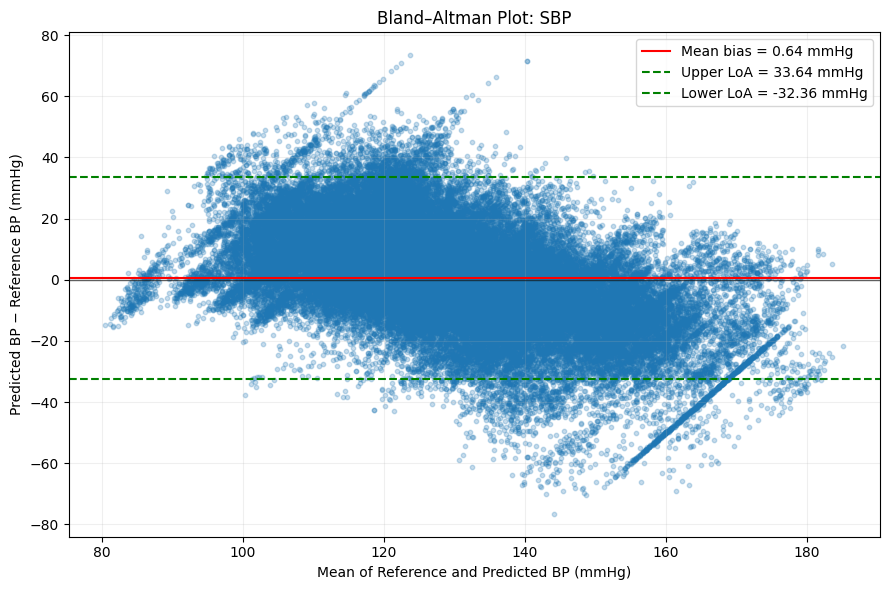


SBP Bland–Altman Statistics
Valid samples:       67085
Mean bias:           0.641 mmHg
SD of differences:   16.837 mmHg
Upper LoA:           33.641 mmHg
Lower LoA:           -32.359 mmHg


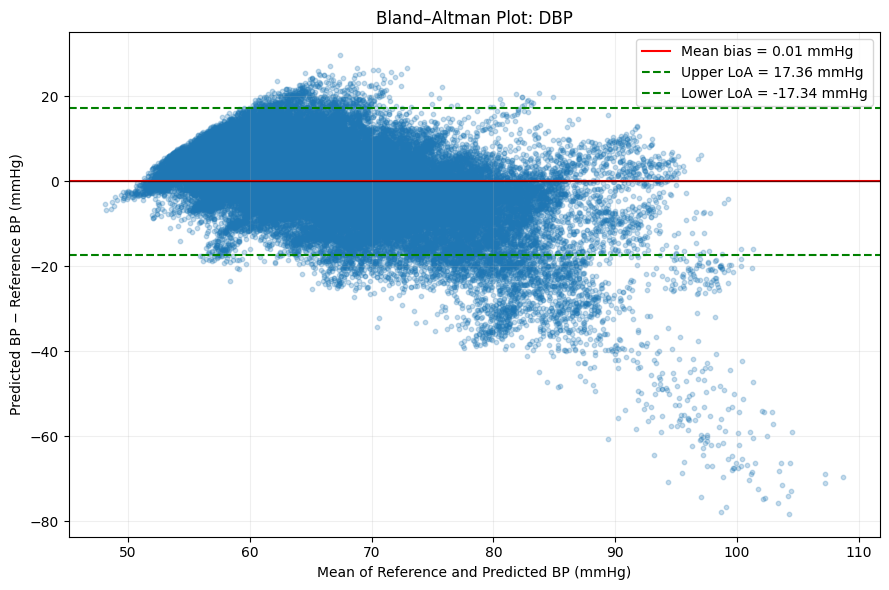


DBP Bland–Altman Statistics
Valid samples:       67085
Mean bias:           0.009 mmHg
SD of differences:   8.851 mmHg
Upper LoA:           17.357 mmHg
Lower LoA:           -17.339 mmHg


In [12]:

import numpy as np
import matplotlib.pyplot as plt

def bland_altman_plot(y_true, y_pred, bp_name="SBP"):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)

    # Remove invalid pairs
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid]
    y_pred = y_pred[valid]

    # Bland-Altman calculations
    mean_bp = (y_true + y_pred) / 2
    differences = y_pred - y_true

    bias = np.mean(differences)
    sd_diff = np.std(differences, ddof=1)

    upper_loa = bias + 1.96 * sd_diff
    lower_loa = bias - 1.96 * sd_diff

    # Plot
    plt.figure(figsize=(9, 6))
    plt.scatter(mean_bp, differences, alpha=0.25, s=10)

    plt.axhline(bias, color="red", linestyle="-",
                label=f"Mean bias = {bias:.2f} mmHg")
    plt.axhline(upper_loa, color="green", linestyle="--",
                label=f"Upper LoA = {upper_loa:.2f} mmHg")
    plt.axhline(lower_loa, color="green", linestyle="--",
                label=f"Lower LoA = {lower_loa:.2f} mmHg")
    plt.axhline(0, color="black", linewidth=1, alpha=0.6)

    plt.xlabel("Mean of Reference and Predicted BP (mmHg)")
    plt.ylabel("Predicted BP − Reference BP (mmHg)")
    plt.title(f"Bland–Altman Plot: {bp_name}")
    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

    print(f"\n{bp_name} Bland–Altman Statistics")
    print(f"Valid samples:       {len(differences)}")
    print(f"Mean bias:           {bias:.3f} mmHg")
    print(f"SD of differences:   {sd_diff:.3f} mmHg")
    print(f"Upper LoA:           {upper_loa:.3f} mmHg")
    print(f"Lower LoA:           {lower_loa:.3f} mmHg")

    return {
        "bias": bias,
        "sd_diff": sd_diff,
        "upper_loa": upper_loa,
        "lower_loa": lower_loa,
        "n": len(differences),
    }



# Generate plots
ba_sbp = bland_altman_plot(
    y_test_sbp, y_pred_sbp, bp_name="SBP"
)

ba_dbp = bland_altman_plot(
    y_test_dbp, y_pred_dbp, bp_name="DBP"
)

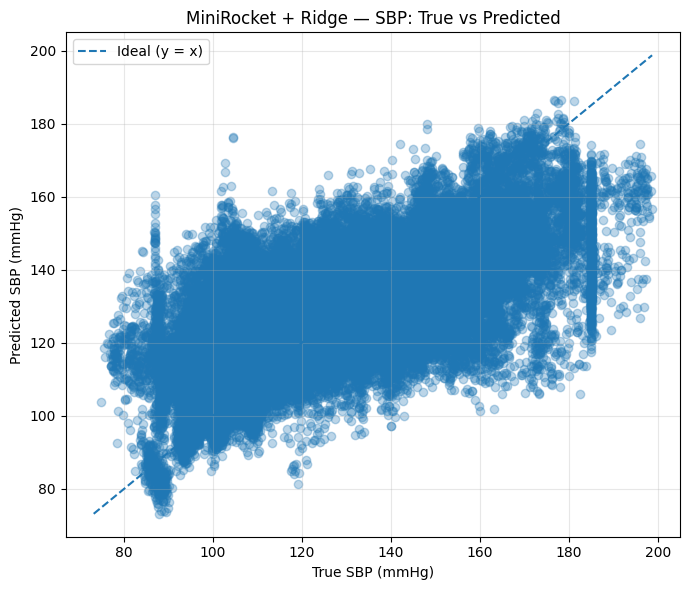

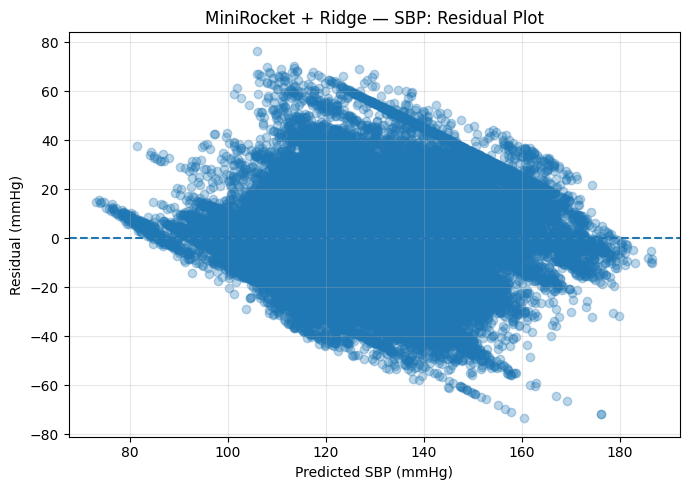

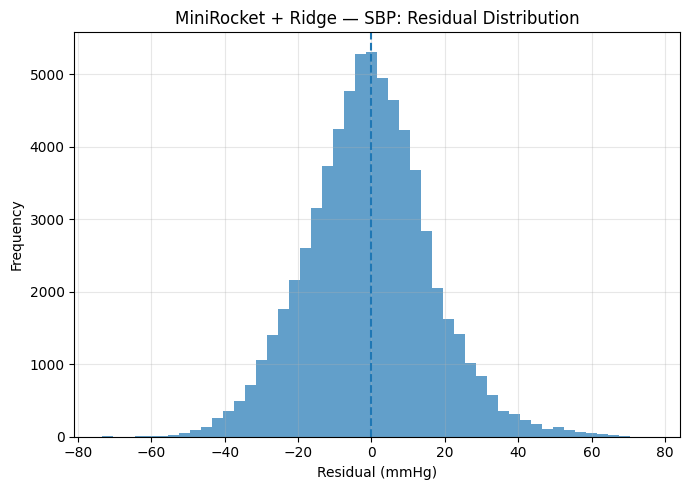

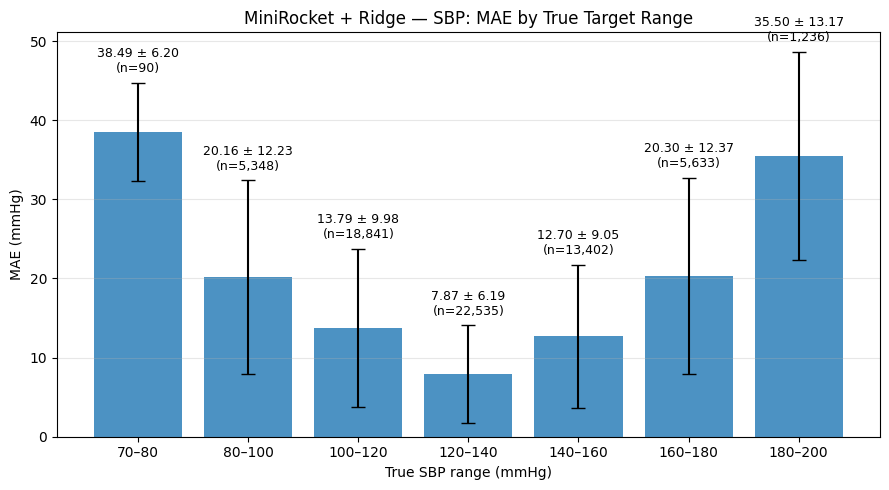

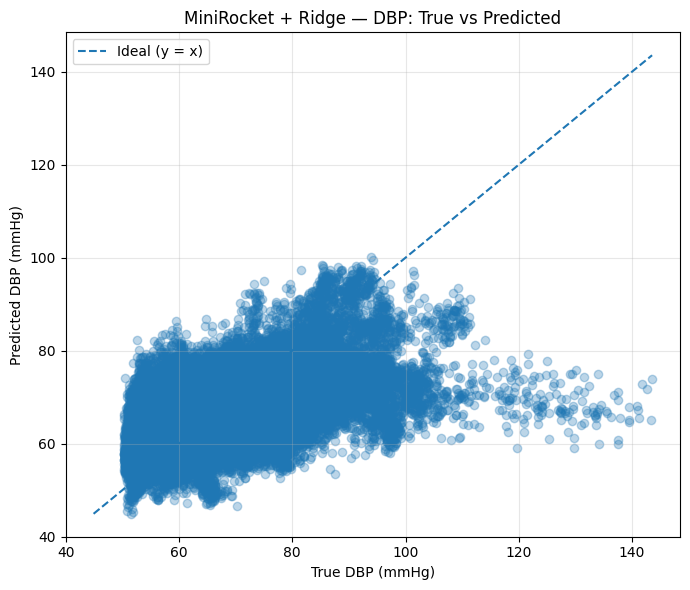

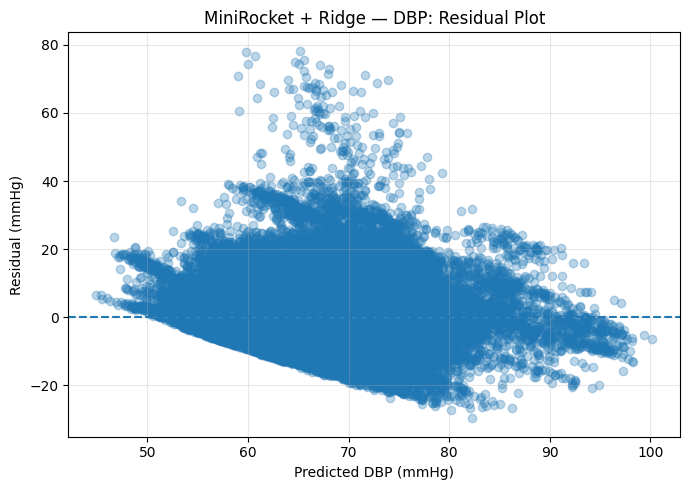

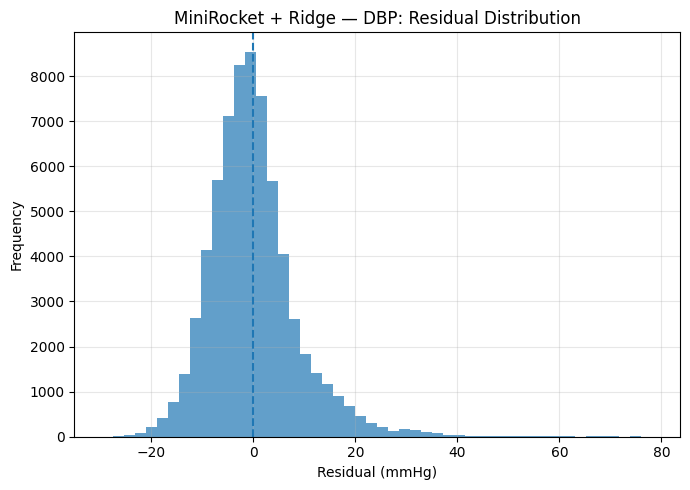

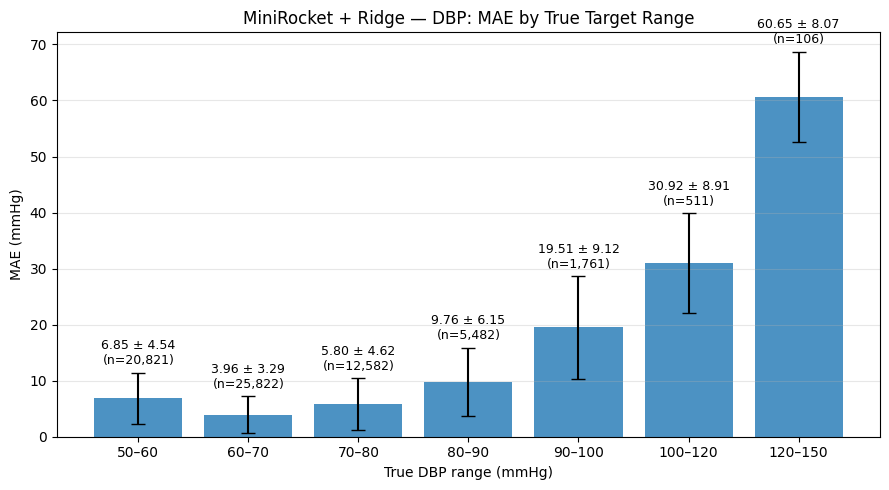

In [13]:
plot_regression_results(
    y_test_sbp,
    y_pred_sbp,
    "MiniRocket + Ridge",
    "SBP"
)

plot_regression_results(
    y_test_dbp,
    y_pred_dbp,
    "MiniRocket + Ridge",
    "DBP"
)

Number of VitalDB cases: 1962


MiniROCKET VitalDB prediction: 100%|██████████| 1962/1962 [1:06:25<00:00,  2.03s/case]




MiniROCKET + Ridge
VITALDB ZERO-SHOT RESULTS

SBP
------------------------------
RMSE: 26.2964
MSE : 691.4995
R²  : -0.6211
MAE : 19.1623

DBP
------------------------------
RMSE: 14.5472
MSE : 211.6209
R²  : -0.3082
MAE : 11.3423


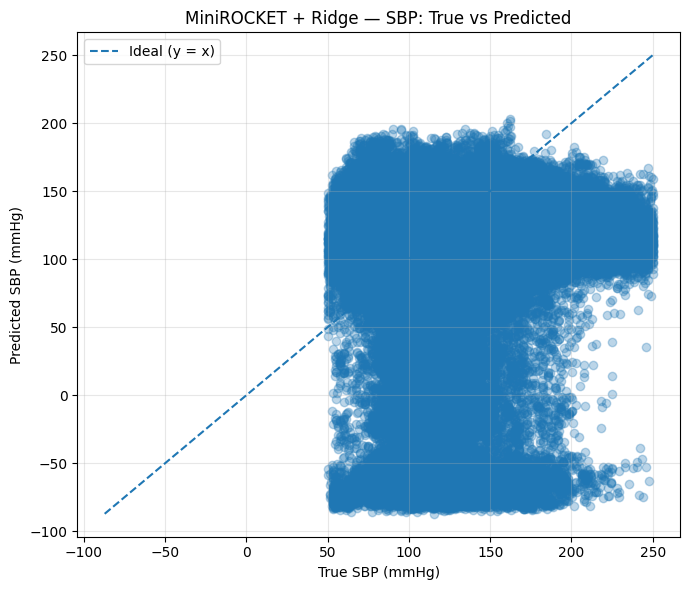

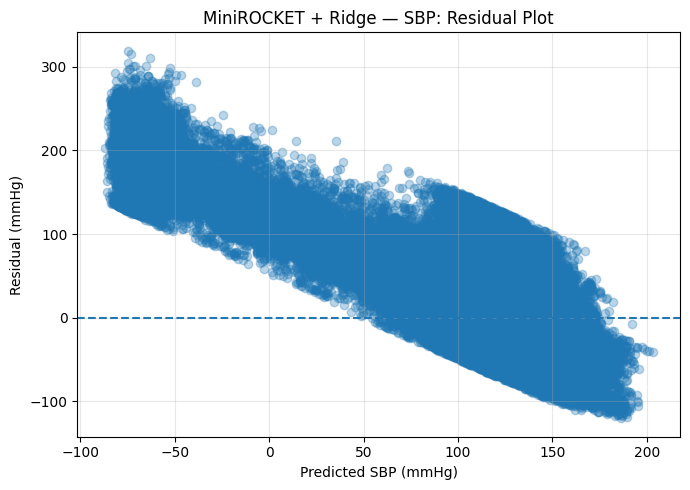

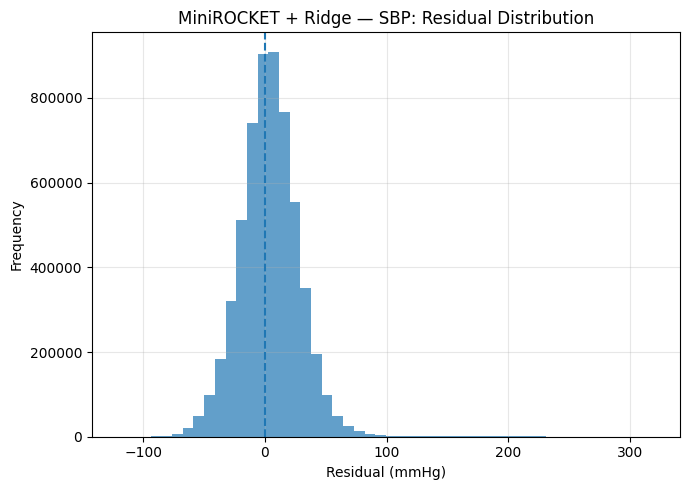

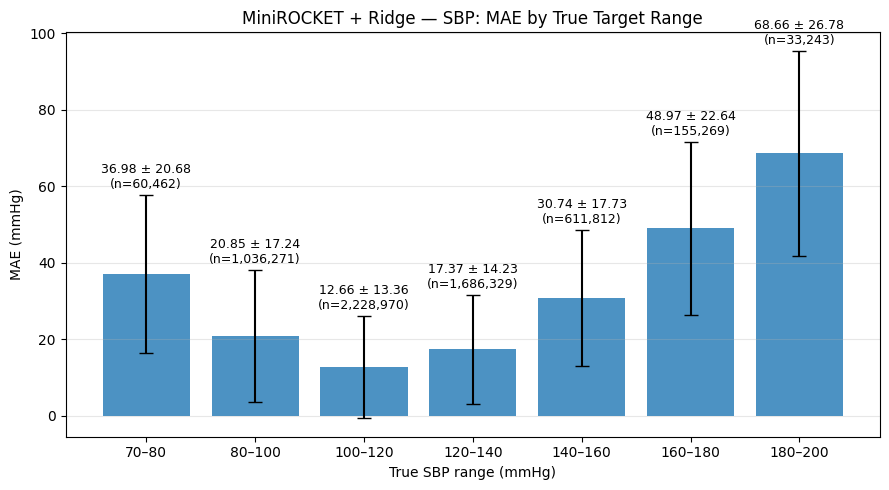

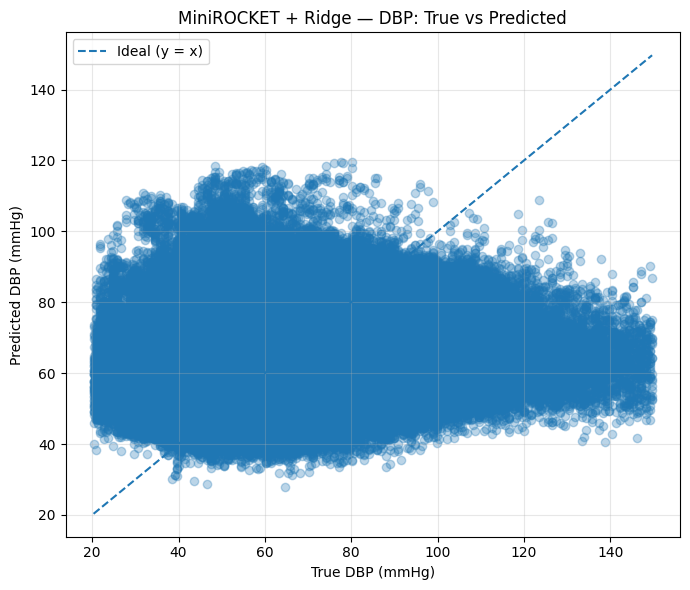

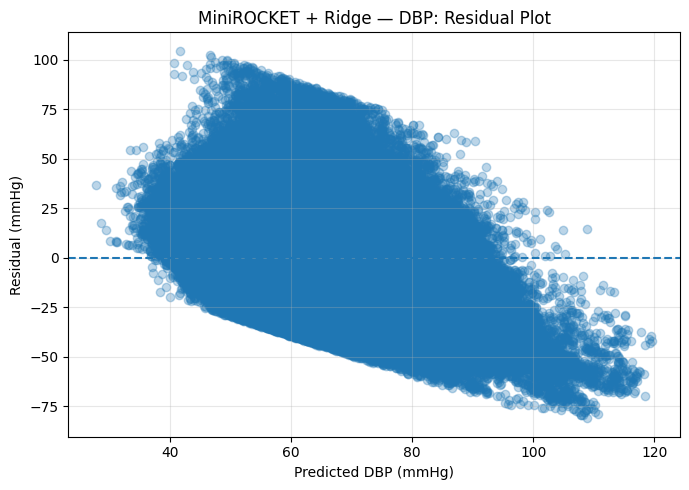

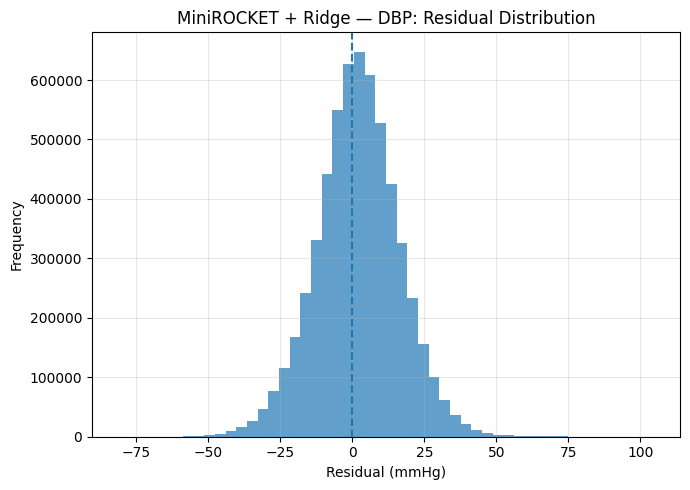

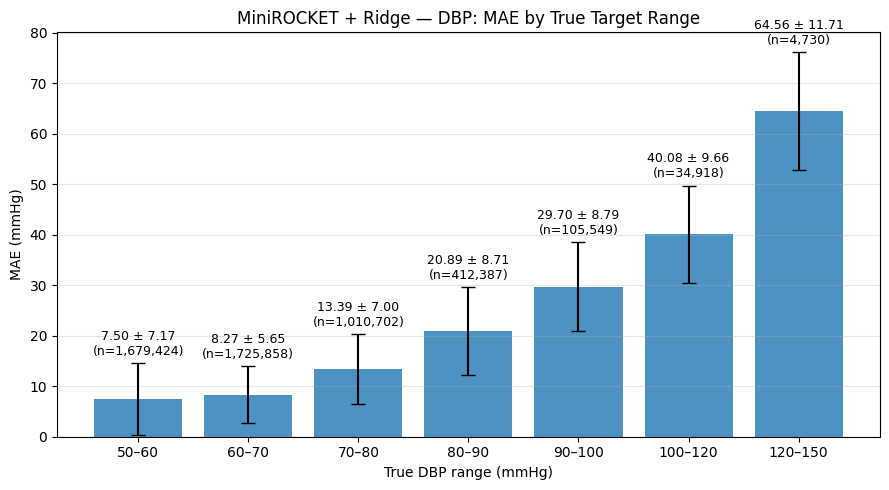


Final prediction shape:
(5837176, 5)

First 5 predictions:
  case_id    SBP_true    SBP_pred   DBP_true   DBP_pred
0  case_1  171.894928  115.524956  76.111603  58.395580
1  case_1  169.920013  114.018562  77.099091  56.995934
2  case_1  169.426300  117.208565  76.111603  59.804234
3  case_1  170.907501  121.491501  75.124176  61.831165
4  case_1  170.907501  121.669937  75.124176  61.549374


In [14]:
results_vitaldb = evaluate_minirocket_vitaldb(
    base_dir=BASE_DIR,
    rocket=rocket,
    best_en_sbp=grid_ridge_sbp,
    best_en_dbp=grid_ridge_dbp,
    model = "Ridge",
    batch_size=5000
)

## MLP ##

In [15]:
mlp_sbp, mlp_dbp = train_mlp(X_train_rocket, y_train, X_val_rocket, y_val)

epoch 00 | TRAIN loss 0.2222 MSE(SBP 241.04, DBP 67.42) RMSE(SBP 15.53, DBP 8.21) | VAL loss 0.2503 MSE(SBP 281.86, DBP 74.08) RMSE(SBP 16.79, DBP 8.61)


epoch 01 | TRAIN loss 0.1840 MSE(SBP 192.46, DBP 56.96) RMSE(SBP 13.87, DBP 7.55) | VAL loss 0.2318 MSE(SBP 260.03, DBP 69.03) RMSE(SBP 16.13, DBP 8.31)


epoch 02 | TRAIN loss 0.1679 MSE(SBP 174.62, DBP 52.78) RMSE(SBP 13.21, DBP 7.27) | VAL loss 0.2270 MSE(SBP 255.88, DBP 68.67) RMSE(SBP 16.00, DBP 8.29)


epoch 03 | TRAIN loss 0.1553 MSE(SBP 157.84, DBP 48.92) RMSE(SBP 12.56, DBP 6.99) | VAL loss 0.2206 MSE(SBP 248.50, DBP 66.73) RMSE(SBP 15.76, DBP 8.17)


epoch 04 | TRAIN loss 0.1437 MSE(SBP 144.14, DBP 45.95) RMSE(SBP 12.01, DBP 6.78) | VAL loss 0.2126 MSE(SBP 236.17, DBP 65.03) RMSE(SBP 15.37, DBP 8.06)


...

epoch 25 | TRAIN loss 0.0810 MSE(SBP 76.50, DBP 26.00) RMSE(SBP 8.75, DBP 5.10) | VAL loss 0.1885 MSE(SBP 209.63, DBP 57.87) RMSE(SBP 14.48, DBP 7.61)


epoch 26 | TRAIN loss 0.0801 MSE(SBP 75.47, DBP 25.81) RMSE(SBP 8.69, DBP 5.08) | VAL loss 0.1921 MSE(SBP 214.24, DBP 58.82) RMSE(SBP 14.64, DBP 7.67)


epoch 27 | TRAIN loss 0.0788 MSE(SBP 74.80, DBP 25.13) RMSE(SBP 8.65, DBP 5.01) | VAL loss 0.1904 MSE(SBP 210.36, DBP 58.95) RMSE(SBP 14.50, DBP 7.68)


epoch 28 | TRAIN loss 0.0786 MSE(SBP 74.12, DBP 25.12) RMSE(SBP 8.61, DBP 5.01) | VAL loss 0.1888 MSE(SBP 209.44, DBP 57.98) RMSE(SBP 14.47, DBP 7.61)


epoch 29 | TRAIN loss 0.0750 MSE(SBP 70.72, DBP 24.03) RMSE(SBP 8.41, DBP 4.90) | VAL loss 0.1893 MSE(SBP 210.27, DBP 58.24) RMSE(SBP 14.50, DBP 7.63)


In [16]:
y_pred_sbp = batch_predict(mlp_sbp, X_test_rocket)
y_pred_dbp = batch_predict(mlp_dbp, X_test_rocket)
print_metrics(y_test[:, 0], y_pred_sbp)
print_metrics(y_test[:, 1], y_pred_dbp)

RMSE: 14.2269
MSE : 202.4041
R²  : 0.5858
MAE : 10.0721
RMSE: 7.8348
MSE : 61.3840
R²  : 0.4771
MAE : 5.1343


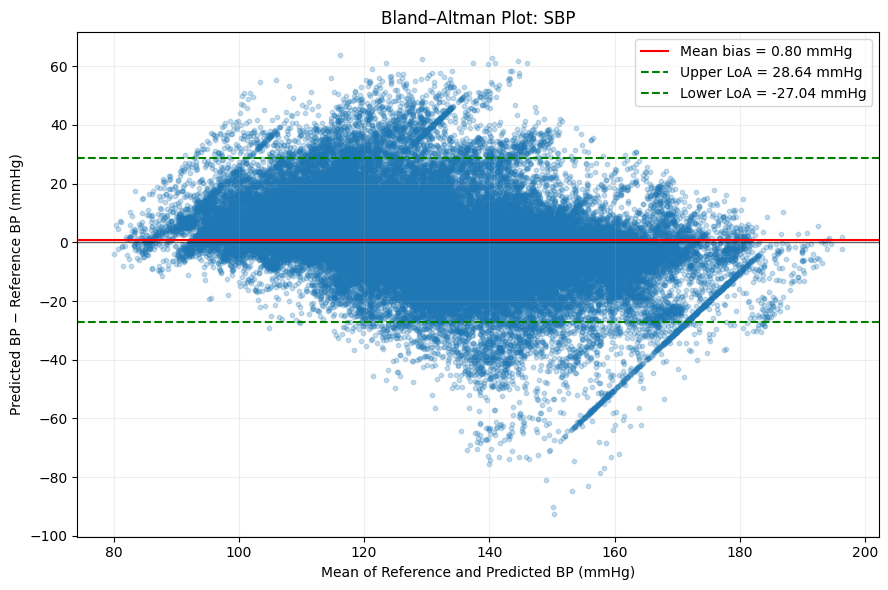


SBP Bland–Altman Statistics
Valid samples:       67085
Mean bias:           0.799 mmHg
SD of differences:   14.205 mmHg
Upper LoA:           28.640 mmHg
Lower LoA:           -27.042 mmHg


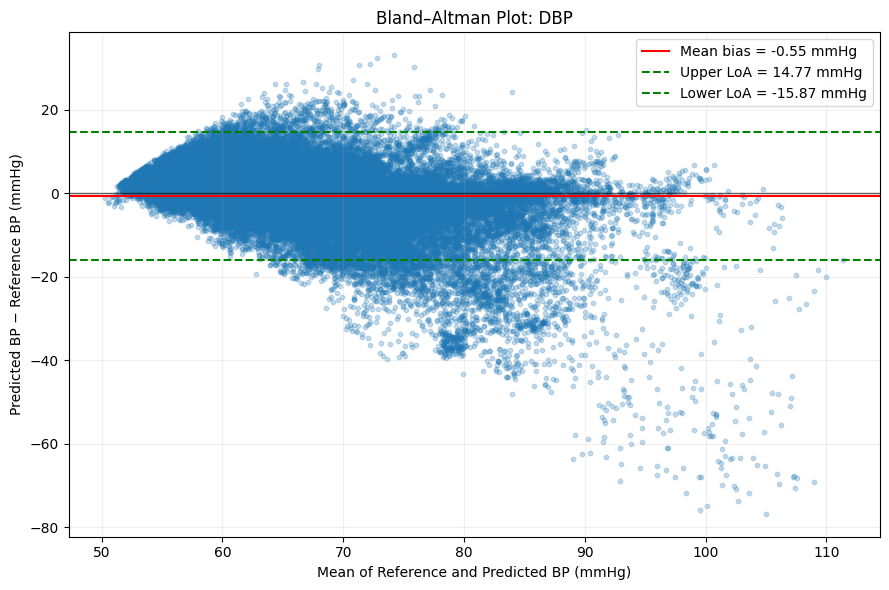


DBP Bland–Altman Statistics
Valid samples:       67085
Mean bias:           -0.552 mmHg
SD of differences:   7.815 mmHg
Upper LoA:           14.767 mmHg
Lower LoA:           -15.870 mmHg


In [17]:
# Generate plots
ba_sbp = bland_altman_plot(
    y_test_sbp, y_pred_sbp, bp_name="SBP"
)

ba_dbp = bland_altman_plot(
    y_test_dbp, y_pred_dbp, bp_name="DBP"
)

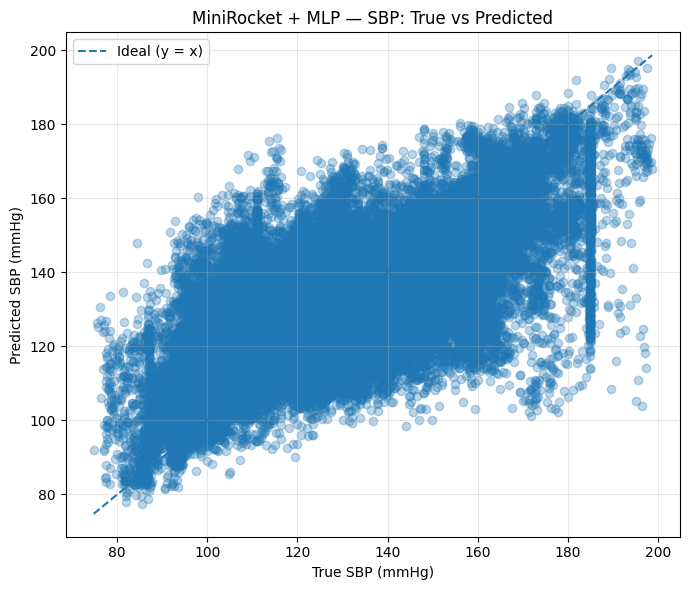

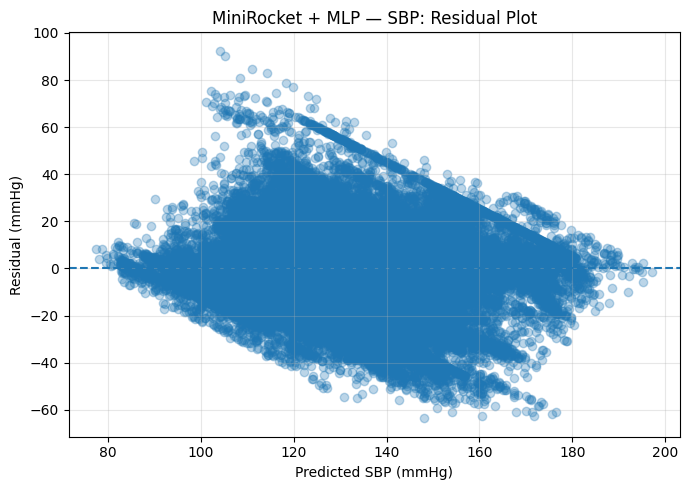

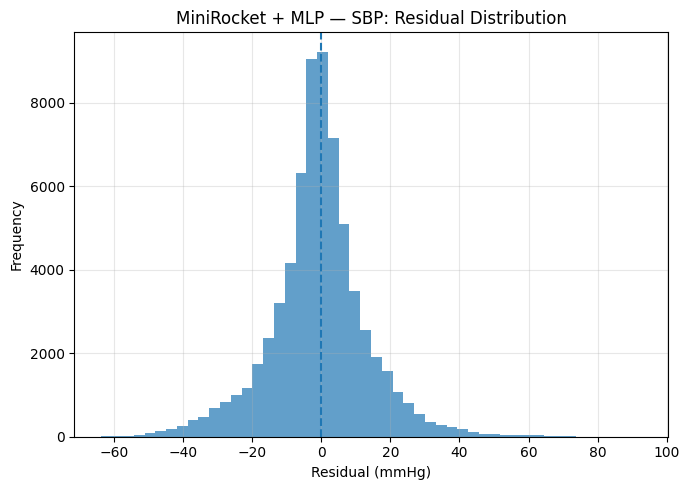

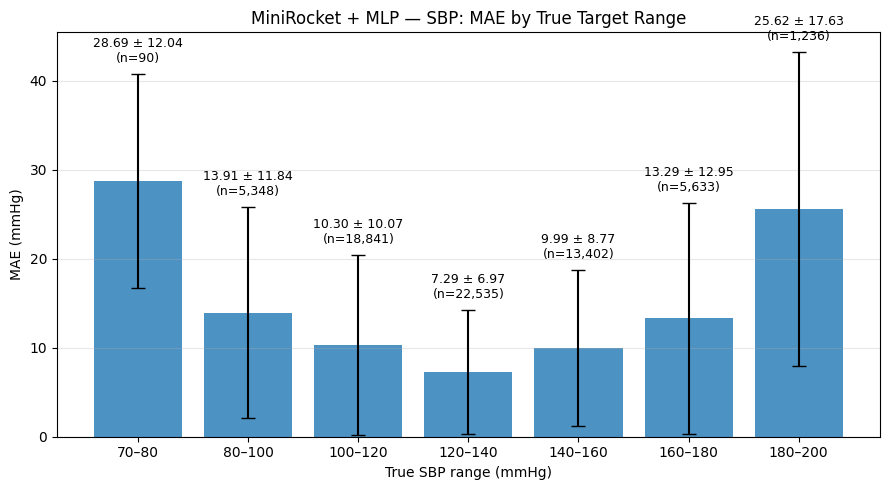

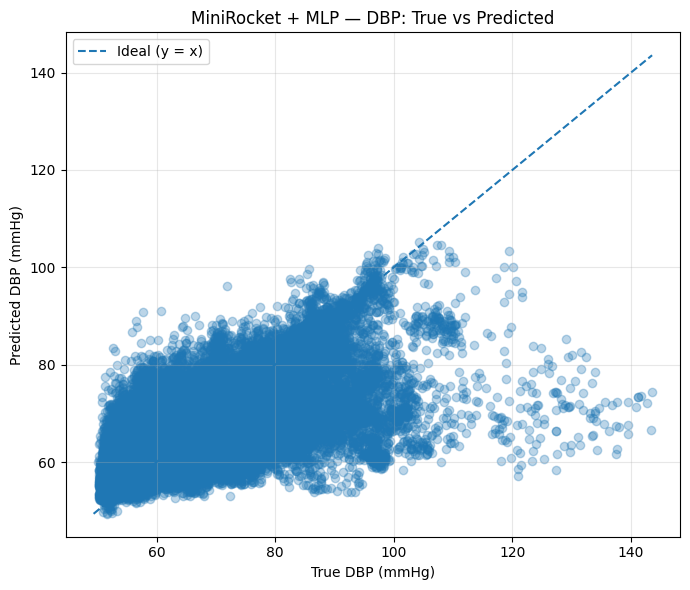

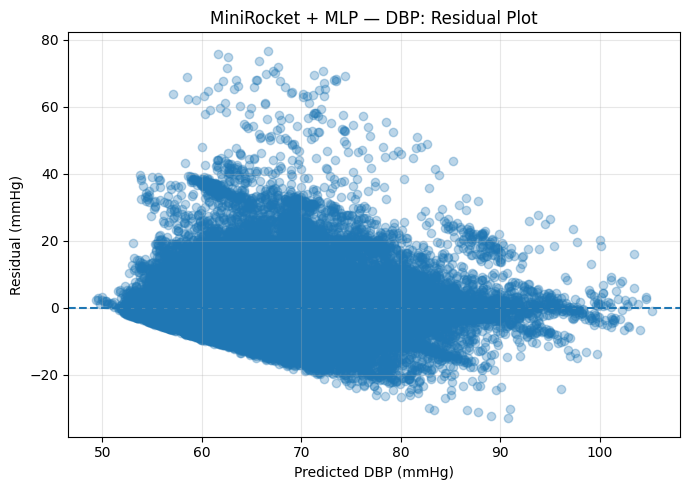

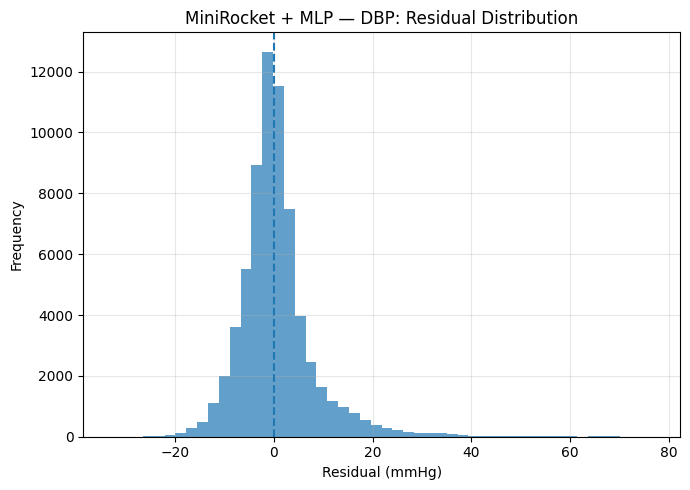

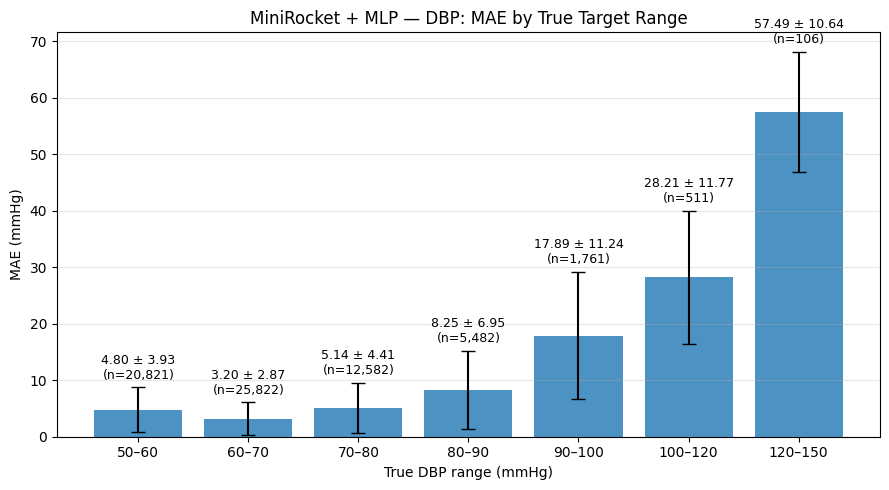

In [18]:
plot_regression_results(
    y_test_sbp,
    y_pred_sbp,
    "MiniRocket + MLP",
    "SBP"
)

plot_regression_results(
    y_test_dbp,
    y_pred_dbp,
    "MiniRocket + MLP",
    "DBP"
)

Number of VitalDB cases: 1962


MiniROCKET VitalDB prediction: 100%|██████████| 1962/1962 [1:03:49<00:00,  1.95s/case]




MiniROCKET + MLP
VITALDB ZERO-SHOT RESULTS

SBP
------------------------------
RMSE: 24.6239
MSE : 606.3375
R²  : -0.4214
MAE : 19.8099

DBP
------------------------------
RMSE: 13.1095
MSE : 171.8588
R²  : -0.0624
MAE : 10.4068


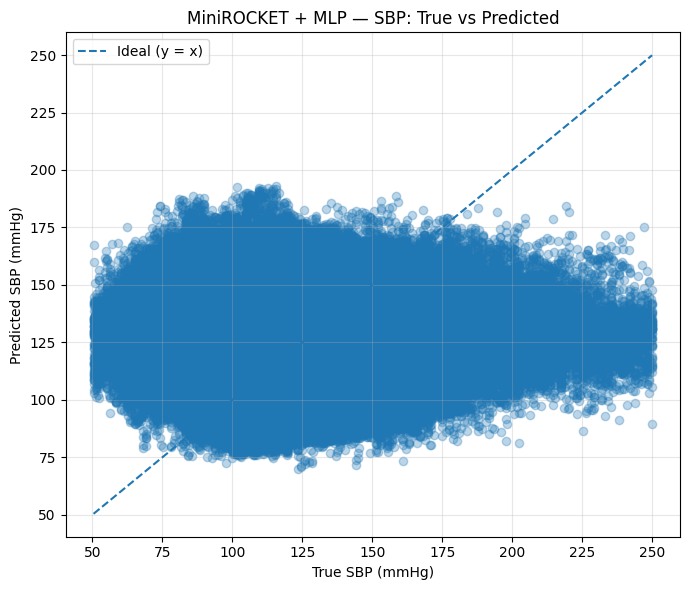

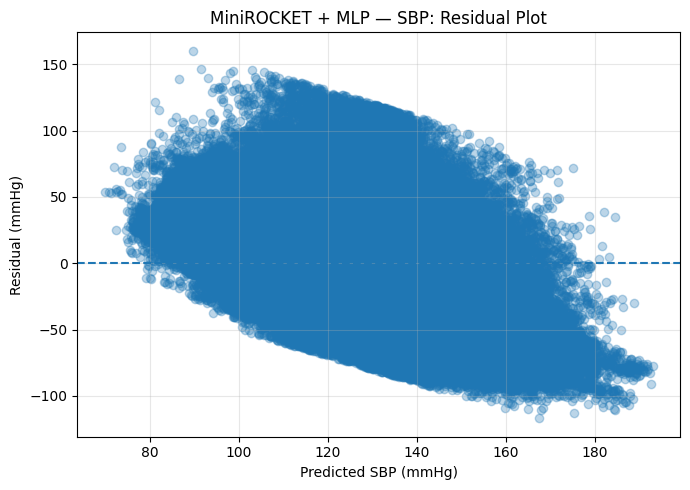

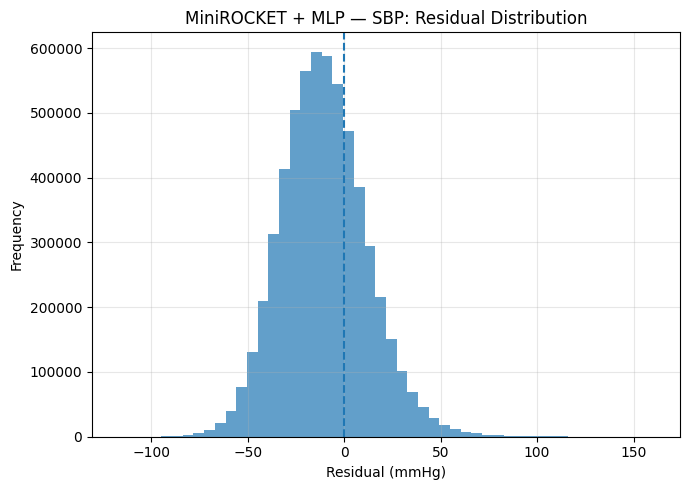

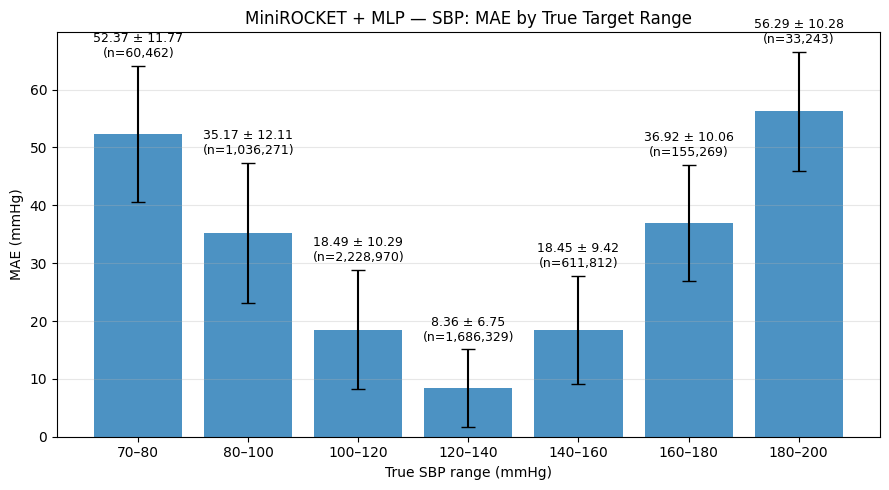

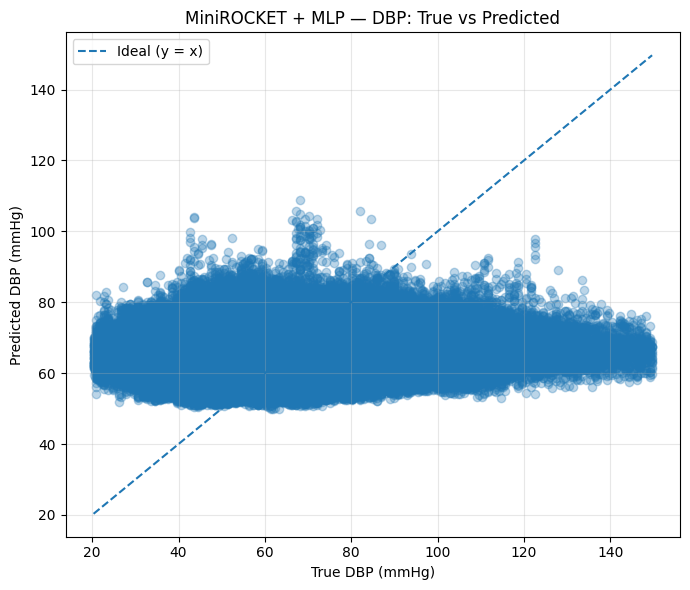

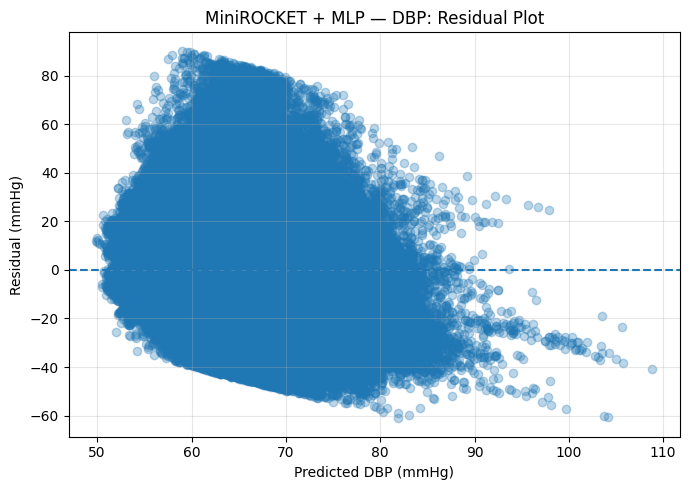

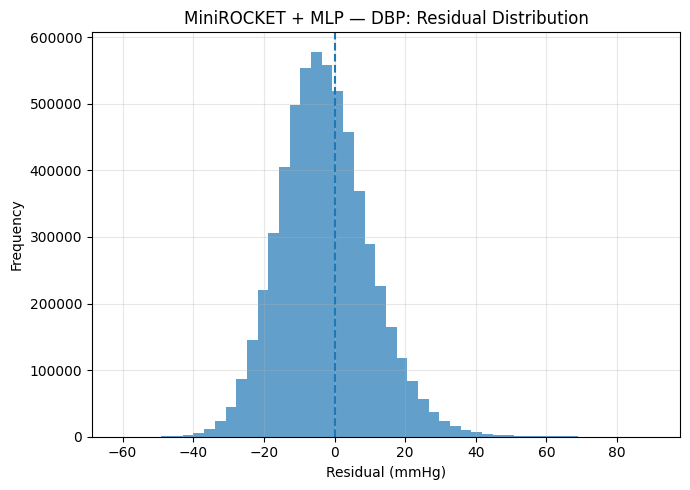

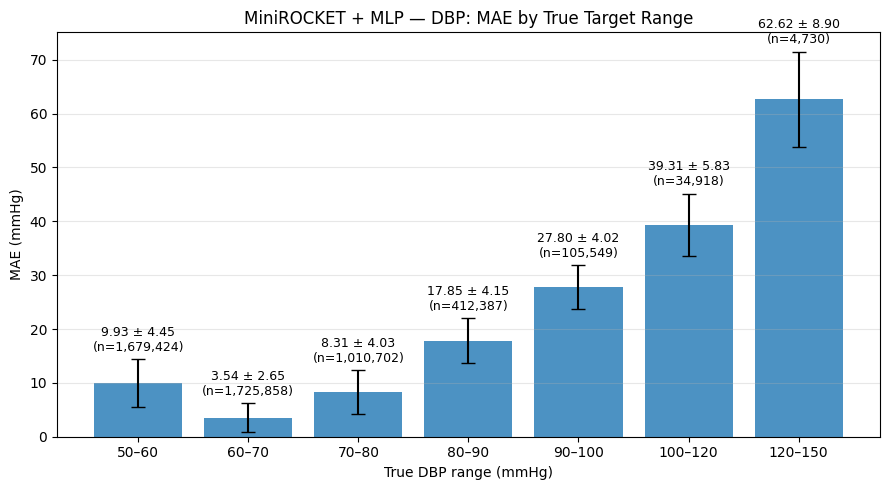


Final prediction shape:
(5837176, 5)

First 5 predictions:
  case_id    SBP_true    SBP_pred   DBP_true   DBP_pred
0  case_1  171.894928  116.682358  76.111603  64.616722
1  case_1  169.920013  117.899162  77.099091  65.287514
2  case_1  169.426300  115.509483  76.111603  64.630646
3  case_1  170.907501  117.285530  75.124176  64.157608
4  case_1  170.907501  116.983269  75.124176  64.266205


In [19]:
results_vitaldb = evaluate_minirocket_vitaldb(
    base_dir=BASE_DIR, rocket=rocket,
    best_en_sbp=mlp_sbp, best_en_dbp=mlp_dbp, model = "MLP", batch_size=2000)

## Feature Selection ##

In [20]:
sbp_idx, sbp_corr = select_top_pearson_features(
    X_train_rocket,
    y_train[:, 0],
    k=1000
)

dbp_idx, dbp_corr = select_top_pearson_features(
    X_train_rocket,
    y_train[:, 1],
    k=1000
)

In [21]:
print("SBP top features:", sbp_idx[:20])
print("SBP correlations:", sbp_corr[:20])

print("DBP top features:", dbp_idx[:20])
print("DBP correlations:", dbp_corr[:20])

SBP top features: [1554  256  233  972  962  438  430  509  496 1082  645  339  553  212
  174 1425  527 1064  259 1479]
SBP correlations: [-0.24592268 -0.24477749 -0.24339676  0.24092937  0.23941936  0.23478028
  0.23325455  0.23126881  0.228682    0.22779147  0.22580203  0.22531112
  0.22452594 -0.22385979  0.22385658  0.22310755  0.22226676  0.22216898
 -0.22196078 -0.22108556]
DBP top features: [2102  383 1157  239  526  388  641 1102  213 1686 1069  555 1159  411
  231  550  437  649  980  218]
DBP correlations: [ 0.23980282 -0.22460848  0.22185932 -0.22166616  0.22023383 -0.21970591
  0.21896324  0.21869533 -0.2183315   0.21793257 -0.21690957  0.2157305
  0.21420874  0.21234278 -0.21182097  0.21013524  0.21011354  0.2087497
 -0.20713572 -0.20393676]
